<a href="https://colab.research.google.com/github/MauveMoose/GameSalesAnalysis/blob/main/IndieSalesAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/vgchartz-2024-indies.csv', low_memory=False)

In [3]:
df.head()

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update,sales_source
0,/games/boxart/full_3450397AmericaFrontccc.png,Minecraft,All,Action-Adventure,Mojang,Mojang AB,NaN,425.00,NaN,NaN,NaN,NaN,2011-11-18,2020-10-08,Official: Mojang / Microsoft / Wikipedia Best-...
1,/games/boxart/full_9847529AmericaFrontccc.jpg,Terraria,All,Platform,Re-Logic,Re-Logic,NaN,58.70,NaN,NaN,NaN,NaN,2011-05-16,2020-10-10,Official: Re-Logic / Wikipedia Best-Selling Vi...
2,/games/boxart/full_1508029AmericaFrontccc.jpg,Human: Fall Flat,All,Platform,Curve Digital,No Brakes Games,NaN,58.00,NaN,NaN,NaN,NaN,2016-07-22,2021-02-11,Official: Curve Games / Wikipedia Best-Selling...
3,/games/boxart/full_5231414AmericaFrontccc.png,Stardew Valley,All,Simulation,ConcernedApe,ConcernedApe,NaN,50.00,NaN,NaN,NaN,NaN,2016-02-26,2020-12-28,Official: ConcernedApe / Wikipedia Best-Sellin...
4,/games/boxart/full_terraria_497AmericaFront.jpg,Terraria,PC,Platform,Re-Logic,Re-Logic,8.8,36.36,NaN,NaN,NaN,NaN,2011-05-16,2018-03-19,Steam Analytics: Gamalytic (PC copiesSold)


In [4]:
df['total_sales'].describe()


,total_sales
count,14703.000000
mean,0.219820
std,3.732667
min,0.000000
25%,0.010000
50%,0.020000
75%,0.070000
max,425.000000


In [5]:
df['na_sales'].describe()


,na_sales
count,70.000000
mean,0.185429
std,0.507328
min,0.000000
25%,0.030000
50%,0.050000
75%,0.097500
max,3.230000


In [6]:
df['jp_sales'].describe()



,jp_sales
count,21.000000
mean,0.154286
std,0.294764
min,0.010000
25%,0.010000
50%,0.010000
75%,0.090000
max,1.250000


In [7]:
df['pal_sales'].describe()


,pal_sales
count,55.000000
mean,0.210182
std,0.604773
min,0.000000
25%,0.010000
50%,0.030000
75%,0.085000
max,3.130000


In [8]:
df['other_sales'].describe()

,other_sales
count,95.000000
mean,0.040421
std,0.149694
min,0.000000
25%,0.000000
50%,0.010000
75%,0.020000
max,0.990000


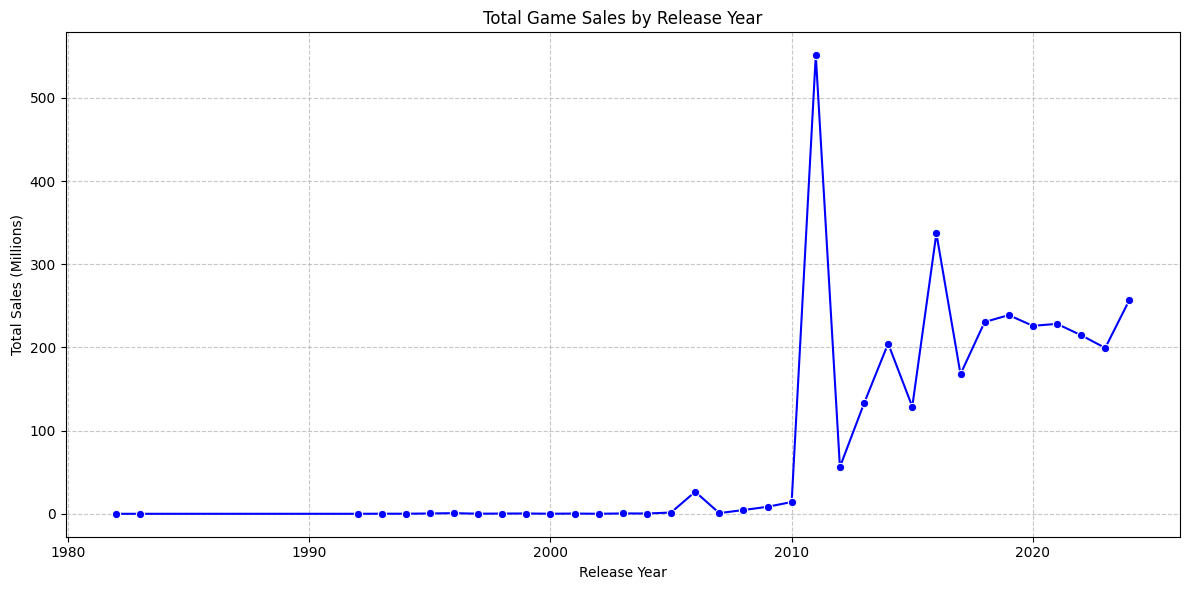

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure release_date is a datetime objects and extract the release year
df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

# Group sales by release year
yearly_sales = df.groupby('release_year')['total_sales'].sum().reset_index()

# Filter out extreme future/past years if any data quality issues exist
yearly_sales = yearly_sales[(yearly_sales['release_year'] >= 1980) & (yearly_sales['release_year'] <= 2024)]

# Create the line plot
plt.figure(figsize=(12, 6))
sns.lineplot(data=yearly_sales, x='release_year', y='total_sales', marker='o', color='b')
plt.title('Total Game Sales by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Total Sales (Millions)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

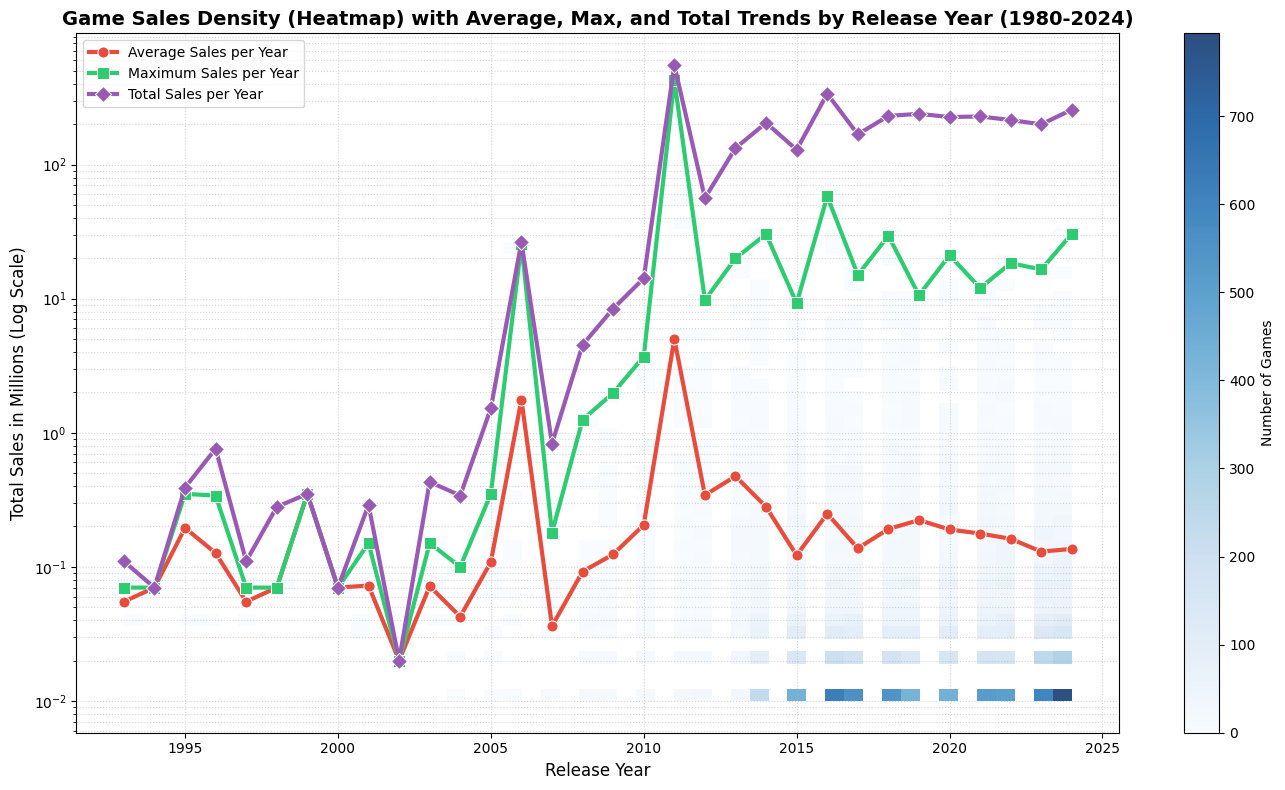

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure release_year column is extracted from release_date first
df['release_year'] = pd.to_datetime(df['release_date'], errors='coerce').dt.year

# Filter out missing years, extreme ranges, and non-positive sales to prevent log scale errors
plot_df = df[
    (df['release_year'] >= 1980) &
    (df['release_year'] <= 2024) &
    (df['total_sales'] > 0)
].dropna(subset=['total_sales'])

# Calculate average, maximum, and total sales by release year using the filtered data
yearly_metrics = plot_df.groupby('release_year')['total_sales'].agg(['mean', 'max', 'sum']).reset_index()

fig, ax = plt.subplots(figsize=(14, 8))

# Create a 2D density heatmap for individual game sales using histplot
sns.histplot(
    data=plot_df,
    x='release_year',
    y='total_sales',
    bins=50,
    log_scale=(False, True),
    cmap='Blues',
    cbar=True,
    cbar_kws={'label': 'Number of Games'},
    ax=ax,
    alpha=0.85
)

# Overlap the average sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='mean',
    color='#e74c3c',
    linewidth=3,
    marker='o',
    markersize=8,
    label='Average Sales per Year',
    ax=ax
)

# Overlap the maximum sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='max',
    color='#2ecc71',
    linewidth=3,
    marker='s',
    markersize=8,
    label='Maximum Sales per Year',
    ax=ax
)

# Overlap the total sales line
sns.lineplot(
    data=yearly_metrics,
    x='release_year',
    y='sum',
    color='#9b59b6',
    linewidth=3,
    marker='D',
    markersize=8,
    label='Total Sales per Year',
    ax=ax
)

plt.title('Game Sales Density (Heatmap) with Average, Max, and Total Trends by Release Year (1980-2024)', fontsize=14, fontweight='bold')
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Total Sales in Millions (Log Scale)', fontsize=12)
plt.grid(True, which='both', linestyle=':', alpha=0.5)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()